In [102]:
import pandas as pd
data=pd.read_csv("transactions_TP2.csv")
print("Partie 1 — Explorer et vérifier les données")
print("Question 1 :")
print("les cinq premières lignes")
print(data.head())
print("le nombre de lignes et de colonnes =")
print(data.shape)
print("Les types de variables:")
print(data.dtypes)
print("Question 2 :")
pourcentage= (data.isnull().sum()/len(data))*100
T=pd.DataFrame({
    "Nombre de valeur manquante" : data.isnull().sum() ,
    "Pourcentage " : pourcentage 
})
table=T.sort_values(
    by="Pourcentage ",
    ascending = False
)

print (table)
print("Question 3 :")
nb_doublons=data["id_operation"].duplicated().sum()
print("les opérations répétées avec id_operation " ,nb_doublons)
supprime= data.drop_duplicates( subset="id_operation")
print( len(supprime))


Partie 1 — Explorer et vérifier les données
Question 1 :
les cinq premières lignes
  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non 

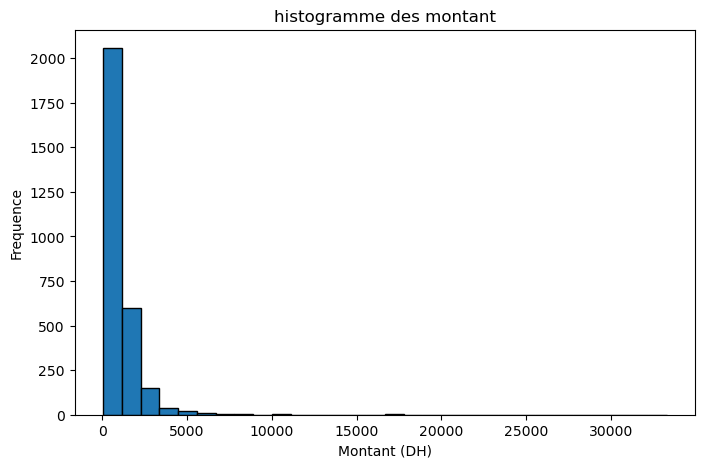

In [103]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(8,5))
plt.hist(supprime["montant_dh"].dropna(),bins=30,edgecolor="black")
plt.title("histogramme des montant")
plt.xlabel("Montant (DH)")
plt.ylabel("Frequence")
plt.show()

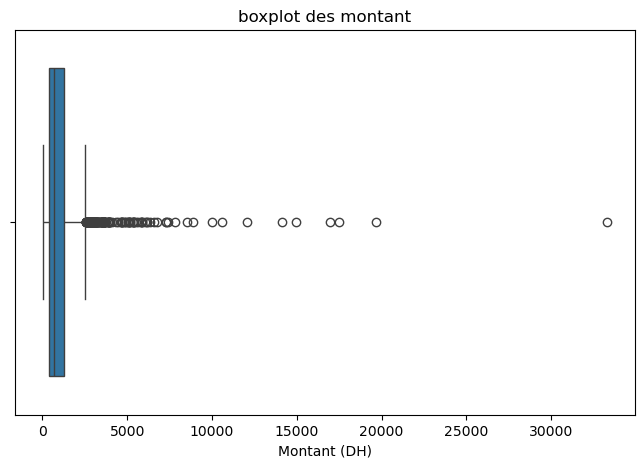

In [104]:
import seaborn as sns
plt.figure(figsize=(8,5))
sns.boxplot(x=supprime["montant_dh"])
plt.title("boxplot des montant")
plt.xlabel("Montant (DH)")
plt.show()

In [105]:
Q1=supprime["montant_dh"].quantile(0.25)
Q3=supprime["montant_dh"].quantile(0.75)
IQR= Q3-Q1
L= Q1-1.5*IQR
U= Q1+1.5*IQR
print("Q1 =",Q1)
print("Q3 =",Q3)
print("IQR=",IQR)
print("L = ",L)
print("U = ",U)
val_aberrant= supprime[
(supprime["montant_dh"]< L) |(supprime["montant_dh"]>U)
]
print("Nombre de montant extreme :", len(val_aberrant))
print("Quelques montants extremes :")
print(val_aberrant["montant_dh"].head(10))


Q1 = 389.53
Q3 = 1249.48
IQR= 859.95
L =  -900.3950000000002
U =  1679.4550000000002
Nombre de montant extreme : 433
Quelques montants extremes :
0      5396.62
2      2846.79
7      2260.29
29     1829.59
32    10598.93
45     2943.87
46     1758.80
50     1856.64
65    14135.85
68     1772.15
Name: montant_dh, dtype: float64


In [106]:
print("Nombre de traction par class:")
print(supprime["fraude"].value_counts())
print("Calculer le pourcentage de chaque class")
pour=(supprime["fraude"].value_counts()/len(supprime))*100

print(pour)
pour=(supprime["fraude"].value_counts()[1]/len(supprime))*100
print("le pourcentage de fraude=1 :" ,pour)



Nombre de traction par class:
fraude
0    2742
1     258
Name: count, dtype: int64
Calculer le pourcentage de chaque class
fraude
0    91.4
1     8.6
Name: count, dtype: float64
le pourcentage de fraude=1 : 8.6


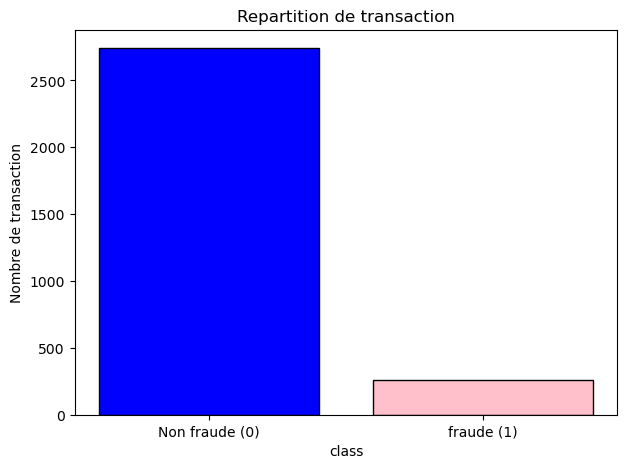

In [107]:
classe= supprime["fraude"].value_counts().sort_index()
plt.figure(figsize=(7 ,5))
plt.bar(
    ["Non fraude (0)","fraude (1)"],
    classe.values,
    color=["blue","pink"],
    edgecolor="black"
)
plt.title("Repartition de transaction")
plt.xlabel("class")
plt.ylabel("Nombre de transaction")
plt.show()

In [108]:
print(supprime.columns)

Index(['id_operation', 'id_client', 'montant_dh', 'anciennete_mois',
       'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international',
       'resultat_enquete', 'fraude'],
      dtype='object')


In [109]:
print("les identifiants:")
print(supprime[["id_operation","id_client"]])
print("Resulta de l enquete :")
print(supprime["resultat_enquete"])
x=supprime.drop(columns=["id_operation","id_client","resultat_enquete","fraude"])
y=supprime["fraude"]
print(x.head(10))
print(y.head(10))


les identifiants:
     id_operation id_client
0         OP02438    C10278
1         OP00157    C10019
2         OP01987    C10604
3         OP00207    C10330
4         OP00738    C10380
...           ...       ...
3040      OP02381    C10304
3041      OP02125    C10573
3042      OP00952    C10125
3043      OP00794    C10318
3044      OP02305    C10573

[3000 rows x 2 columns]
Resulta de l enquete :
0          aucune_fraude
1          aucune_fraude
2          aucune_fraude
3          aucune_fraude
4          aucune_fraude
              ...       
3040       aucune_fraude
3041       aucune_fraude
3042    fraude_confirmee
3043       aucune_fraude
3044       aucune_fraude
Name: resultat_enquete, Length: 3000, dtype: object
   montant_dh  anciennete_mois  nb_ops_24h  heure        canal    appareil  \
0     5396.62             90.0         6.0     11     site_web      mobile   
1      438.41             55.0         2.0     22  application      mobile   
2     2846.79              NaN       

In [110]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,stratify=y,random_state=42)
print("les ligne dentrainement : " ,len(x_train))
print("les ligne de test : ",len(x_test))
pou_train=y_train.value_counts(normalize=True)*100
pou_test=y_test.value_counts(normalize=True)*100

comparaison=pd.DataFrame({
    "Groupe d'entrainement(80%)":pou_train,
    "Groupe de test (20%)":pou_test
})
print(comparaison)
print(x_train.shape)


les ligne dentrainement :  2400
les ligne de test :  600
        Groupe d'entrainement(80%)  Groupe de test (20%)
fraude                                                  
0                        91.416667             91.333333
1                         8.583333              8.666667
(2400, 8)


In [111]:
print("Liste de variable numerique:")
print(x.select_dtypes(include=['int64','float64']).columns)
print("Liste de variable categorille:")
print(x.select_dtypes(include=['object','category']).columns)


Liste de variable numerique:
Index(['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure'], dtype='object')
Liste de variable categorille:
Index(['canal', 'appareil', 'region', 'international'], dtype='object')


In [112]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
print("remplacer les valeurs manquantes par la médiane")
val_num=['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
x_train_num=num_pipe.fit_transform(x_train[val_num])
x_test_num=num_pipe.fit_transform(x_test[val_num])

print(x_train_num)
print("Nouvelles dimensions :", x_train_num.shape)
print("Nouvelles dimensions de test :", x_test_num.shape)

remplacer les valeurs manquantes par la médiane
[[-0.45279558 -0.69683119  0.16959525  0.64756193]
 [-0.36731967  0.55605041  1.38460603  1.64820949]
 [-0.40885247 -0.09059816  0.16959525  1.64820949]
 ...
 [ 0.32270931  0.03064845  0.16959525  0.21871297]
 [-0.23341141  0.57625818  0.77710064 -1.21078356]
 [-0.09545835 -0.02997486  0.16959525  1.36231019]]
Nouvelles dimensions : (2400, 4)
Nouvelles dimensions de test : (600, 4)


In [113]:
print(" applique One-hot encoding pour les variable categorielle")
var_cat =['canal', 'appareil', 'region', 'international']
cat_pipe= Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot" , OneHotEncoder(handle_unknown="ignore"))
])
x_train_categ=cat_pipe.fit_transform(x_train[var_cat])
x_test_categ=cat_pipe.fit_transform(x_test[var_cat])

print(x_train_categ.toarray()[:5])
print(" dimensions dentrainement:", x_train_categ.shape)
print(" dimensions de test :", x_test_categ.shape)

 applique One-hot encoding pour les variable categorielle
[[0. 1. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 1.]
 [0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0.]
 [0. 0. 1. 0. 1. 0. 0. 0. 0. 1. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0. 1. 0. 0. 0. 1. 0. 0. 0. 1.]]
 dimensions dentrainement: (2400, 14)
 dimensions de test : (600, 14)


In [114]:
from sklearn.compose import ColumnTransformer
prep= ColumnTransformer([
    ("numeric", num_pipe,val_num),
    ("categorical",cat_pipe,var_cat)
])
x_train_prep=prep.fit_transform(x_train)
x_test_prep=prep.fit_transform(x_test)
print(" dimensions dentrainement:", x_train_prep.shape)
print(" dimensions de test :", x_test_prep.shape)

 dimensions dentrainement: (2400, 18)
 dimensions de test : (600, 18)


In [132]:
from sklearn.preprocessing import RobustScaler,MinMaxScaler
val_num=['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
num_robust_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])
x_train_robust_num=num_robust_pipe.fit_transform(x_train[val_num])
x_test_robust_num=num_robust_pipe.transform(x_test[val_num])

print(x_train_num)
mantant_index=list(val_num).index('montant_dh')
print(x_train['montant_dh'].describe())
print(x_train_robust_num[:10 , mantant_index])

print("Nouvelles dimensions :", x_train_num.shape)
print("Nouvelles dimensions de test :", x_test_num.shape)

[[-0.45279558 -0.69683119  0.16959525  0.64756193]
 [-0.36731967  0.55605041  1.38460603  1.64820949]
 [-0.40885247 -0.09059816  0.16959525  1.64820949]
 ...
 [ 0.32270931  0.03064845  0.16959525  0.21871297]
 [-0.23341141  0.57625818  0.77710064 -1.21078356]
 [-0.09545835 -0.02997486  0.16959525  1.36231019]]
count     2312.000000
mean      1032.467777
std       1351.544802
min         36.410000
25%        393.095000
50%        710.790000
75%       1249.877500
max      33281.230000
Name: montant_dh, dtype: float64
[-0.35673954 -0.21774757 -0.28528385  2.21359544 -0.3871027  -0.06400882
 -0.5632923  -0.35482883 -0.37716945 -0.28303019]
Nouvelles dimensions : (2400, 4)
Nouvelles dimensions de test : (600, 4)


In [116]:
montant=x_train['montant_dh'].dropna()
montant_normal=montant.median()
montant_eleve=montant.max()
val=pd.DataFrame({
    'montant_dh' : [montant_normal,montant_eleve],
    'anciennete_mois':[0,0],
    'nb_ops_24h':[0,0],
    'heure':[0,0]
})
result=num_robust_pipe.transform(val[val_num])
print("une opération ordinaire :",montant_normal)
print("valeur transformée :" ,result[0,mantant_index])
print("une opération au montant très élevé:",montant_eleve)
print("valeur transformée :" ,result[1,mantant_index])


une opération ordinaire : 710.79
valeur transformée : 0.031871846139198294
une opération au montant très élevé: 33281.23
valeur transformée : 38.79512996286776


In [117]:
Q1=x_train["montant_dh"].quantile(0.25)
Q3=x_train["montant_dh"].quantile(0.75)
IQR= Q3-Q1
print("Q1 =",Q1)
print("Q3 =",Q3)
print("IQR=",IQR)

Q1 = 393.095
Q3 = 1249.8775
IQR= 856.7825


In [118]:
L= Q1-1.5*IQR
U= Q1+1.5*IQR
print("L = ",L)
print("U = ",U)
val_aberrant= x_train[
(x_train["montant_dh"]< L) |(x_train["montant_dh"]>U)
]
print("Nombre de montant extreme :", len(val_aberrant))
print("Quelques montants extremes :")
print(val_aberrant["montant_dh"].head(10))


L =  -892.0787499999999
U =  1678.26875
Nombre de montant extreme : 340
Quelques montants extremes :
267     2518.08
2106    1845.59
1261    2372.58
1601    2940.62
1348    3449.17
2736    1711.73
804     2499.73
920     1945.92
345     1683.87
2023    1885.99
Name: montant_dh, dtype: float64


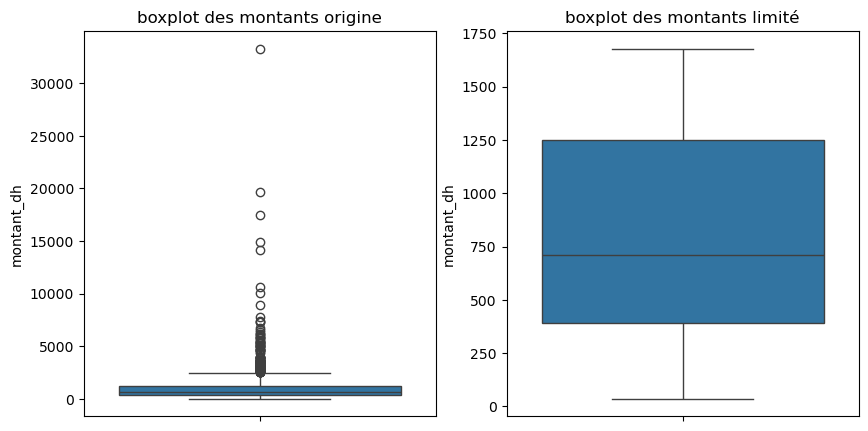

In [119]:
origine_montant=x_train['montant_dh'].dropna()
limit_montant = origine_montant.clip(lower=L,upper=U)
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.boxplot(y=origine_montant)
plt.title("boxplot des montants origine")
plt.subplot(1,2,2)
sns.boxplot(y=limit_montant)
plt.title("boxplot des montants limité")
plt.show()

In [120]:
X_train=x_train[['montant_dh']]
X_test=x_test[['montant_dh']]

minmax=MinMaxScaler()
train_minmax=minmax.fit_transform(X_train)
test_minmax=minmax.transform(X_test)
print("minmax scaler d'entrainement :" , train_minmax[:5])
print("minmax scaler de test :", test_minmax[:5])

standar=StandardScaler()
train_standar=standar.fit_transform(X_train)
test_standar=standar.transform(X_test)
print("standar scaler d'entrainement :" , train_standar[:5])
print("standar scaler de test :", test_standar[:5])

train_robust=x_train_robust_num[:,mantant_index]
test_robust=x_test_robust_num[:, mantant_index]
print("robust scaler d'entrainement :" , train_robust[:5])
print("robust scaler de test :", test_robust[:5])

minmax scaler d'entrainement : [[0.0115242 ]
 [0.01493767]
 [0.01327906]
 [0.07464832]
 [0.01077852]]
minmax scaler de test : [[0.02283333]
 [0.03334204]
 [0.00669849]
 [0.00936657]
 [0.01248164]]
standar scaler d'entrainement : [[-0.45360714]
 [-0.3696258 ]
 [-0.41043238]
 [ 1.09943348]
 [-0.47195308]]
standar scaler de test : [[-0.17536899]
 [ 0.08317633]
 [-0.57233403]
 [-0.50669123]
 [-0.43005122]]
robust scaler d'entrainement : [-0.35673954 -0.21774757 -0.28528385  2.21359544 -0.3871027 ]
robust scaler de test : [ 0.13268828  0.54847425 -0.50570075 -0.40013568 -0.27688518]


In [121]:
montants_choisis = pd.DataFrame({
    'montant_dh': [ Q1, x_train['montant_dh'].median(), Q3, x_train['montant_dh'].max()],
    'anciennete_mois':[0,0,0,0],
    'nb_ops_24h':[0,0,0,0],
    'heure':[0,0,0,0]
})
montants_choisis['MinMaxScaler'] = minmax.transform(
montants_choisis[['montant_dh']]
).flatten()
montants_choisis['StandardScaler'] = standar.transform(montants_choisis[['montant_dh']]).flatten()
result_robust = num_robust_pipe.transform(montants_choisis[val_num])
montants_choisis['RobustScaler'] = result_robust[:, mantant_index]
print(montants_choisis[
['montant_dh', 'MinMaxScaler', 'StandardScaler', 'RobustScaler']
].round(3))

   montant_dh  MinMaxScaler  StandardScaler  RobustScaler
0     393.095         0.011          -0.473        -0.346
1     710.790         0.020          -0.238         0.032
2    1249.878         0.037           0.161         0.673
3   33281.230         1.000          23.866        38.795


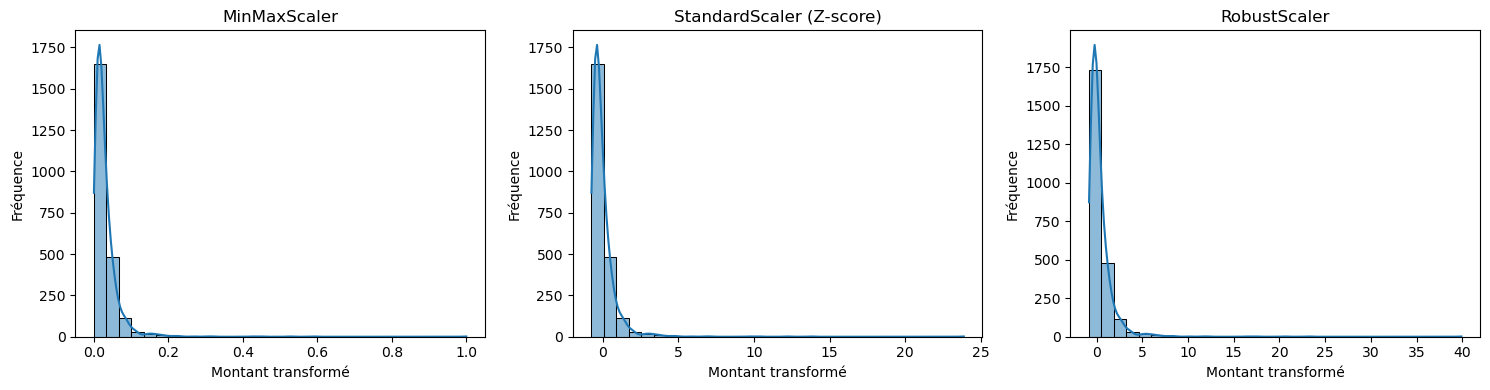

In [122]:
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
sns.histplot(train_minmax.flatten() ,bins=30 , kde=True)
plt.title("MinMaxScaler")
plt.xlabel("Montant transformé")
plt.ylabel("Fréquence")
plt.subplot(1, 3 ,2)
sns.histplot(train_standar.flatten(), bins=30, kde=True)
plt.title("StandardScaler (Z-score)")
plt.xlabel("Montant transformé")
plt.ylabel("Fréquence")
plt.subplot(1, 3 ,3)
sns.histplot(train_robust.flatten(), bins=30, kde=True)
plt.title("RobustScaler")
plt.xlabel("Montant transformé")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()

In [123]:
import numpy as np
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
print("Question 22 : Effectifs des classes")
effectifs = y_train.value_counts().sort_index()
print(effectifs)
rapport = effectifs[0] / effectifs[1]
print("Rapport entre les deux classes :", rapport)

Question 22 : Effectifs des classes
fraude
0    2194
1     206
Name: count, dtype: int64
Rapport entre les deux classes : 10.650485436893204


In [124]:
print("Question 23 :")
print("Avant le suréchantillonnage :")
print(y_train.value_counts().sort_index())
over = RandomOverSampler(random_state=42)
x_train_over, y_train_over = over.fit_resample(x_train, y_train)
print("Après le suréchantillonnage :")
print(y_train_over.value_counts().sort_index())
print("Nombre de lignes avant :", len(y_train))
print("Nombre de lignes après :", len(y_train_over))


Question 23 :
Avant le suréchantillonnage :
fraude
0    2194
1     206
Name: count, dtype: int64
Après le suréchantillonnage :
fraude
0    2194
1    2194
Name: count, dtype: int64
Nombre de lignes avant : 2400
Nombre de lignes après : 4388


In [125]:
print("Question 24 :")
print("Avant le sous-échantillonnage :")
print(y_train.value_counts().sort_index())
under= RandomUnderSampler(random_state=42)
x_train_under, y_train_under = under.fit_resample(x_train, y_train)
print("Après le sous-échantillonnage :")
print(y_train_under.value_counts().sort_index())
print("Nombre de lignes avant :", len(y_train))
print("Nombre de lignes conservées :", len(y_train_under))
print("Nombre de lignes supprimées :", len(y_train) - len(y_train_under))

Question 24 :
Avant le sous-échantillonnage :
fraude
0    2194
1     206
Name: count, dtype: int64
Après le sous-échantillonnage :
fraude
0    206
1    206
Name: count, dtype: int64
Nombre de lignes avant : 2400
Nombre de lignes conservées : 412
Nombre de lignes supprimées : 1988


In [126]:
print("Question 25 :")
X = np.array([
    [2, 4],
    [6, 8],
    [10, 2],
    [12, 3],
    [14, 4],
    [16, 5]
])
y = np.array([1, 1, 0, 0, 0, 0])
print("Avant SMOTE :")
print("Classe 0 :", sum(y == 0))
print("Classe 1 :", sum(y == 1))
smote = SMOTE(random_state=42, k_neighbors=1)
X_smote, y_smote = smote.fit_resample(X, y)
print("Après SMOTE :")
print("Classe 0 :", sum(y_smote == 0))
print("Classe 1 :", sum(y_smote == 1))
print("Observations synthétiques créées :")
print(X_smote[len(X):])

Question 25 :
Avant SMOTE :
Classe 0 : 4
Classe 1 : 2
Après SMOTE :
Classe 0 : 4
Classe 1 : 4
Observations synthétiques créées :
[[5 7]
 [3 5]]


In [127]:
print("Question 27 : ")
tableau = pd.DataFrame({"Avant rééquilibrage": y_train.value_counts().sort_index(),
    "Après RandomOverSampler": y_train_over.value_counts().sort_index(),
    "Après RandomUnderSampler": y_train_under.value_counts().sort_index()
})
tableau.index.name = "Classe de fraude"
print(tableau)
print("Groupe de vérification :")
print(y_test.value_counts().sort_index())
print("Le groupe de vérification reste inchangé.")

Question 27 : 
                  Avant rééquilibrage  Après RandomOverSampler  \
Classe de fraude                                                 
0                                2194                     2194   
1                                 206                     2194   

                  Après RandomUnderSampler  
Classe de fraude                            
0                                      206  
1                                      206  
Groupe de vérification :
fraude
0    548
1     52
Name: count, dtype: int64
Le groupe de vérification reste inchangé.


In [128]:
from sklearn.compose import ColumnTransformer
val_num=['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
var_cat =['canal', 'appareil', 'region', 'international']
num_pipe_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

cat_pipe_final= Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot" , OneHotEncoder(handle_unknown="ignore"))
])
prep_fina=ColumnTransformer([
    ('numeric',num_pipe_final,val_num),
    ('categorical',cat_pipe_final,var_cat)
])
print(prep_fina)


ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', RobustScaler())]),
                                 ['montant_dh', 'anciennete_mois', 'nb_ops_24h',
                                  'heure']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['canal', 'appareil', 'region',
                                  'international'])])


In [129]:
prep_fina.fit(x_train)
x_train_final= prep_fina.transform(x_train)
x_test_final= prep_fina.transform(x_test)
print("nombre de colonne train:" ,x_train_final.shape)
print("nombre de colonne test:" ,x_test_final.shape)
print(np.isnan(x_train_final).sum())
print(np.isnan(x_test_final).sum())
print("verifie de meme nombre de colonne :" ,x_train_final.shape[1]==x_test_final.shape[1])


nombre de colonne train: (2400, 18)
nombre de colonne test: (600, 18)
0
0
verifie de meme nombre de colonne : True


In [130]:
new_ligne=x_train.iloc[[0]].copy()
new_ligne['canal']='inconnu'
print(new_ligne)
new_ligne_transformee= prep_fina.transform(new_ligne)
print(new_ligne_transformee)
print(new_ligne_transformee.shape)

     montant_dh  anciennete_mois  nb_ops_24h  heure    canal appareil  \
384      419.53             53.0         3.0     16  inconnu   mobile   

             region international  
384  Draa-Tafilalet           oui  
[[-0.35673954 -0.4047619   0.          0.38461538  0.          0.
   0.          0.          1.          0.          0.          0.
   0.          1.          0.          0.          0.          1.        ]]
(1, 18)


In [131]:
import joblib
joblib.dump(prep_fina,'preprocessing.pkl')
prep_charge= joblib.load('preprocessing.pkl')
r1=prep_fina.transform(x_test.iloc[:5])
r2=prep_charge.transform(x_test.iloc[:5])
print("Resultat 1 ;", r1)
print("Resultat 2 ;", r2)
print("les resultats sont identique : ", (r1==r2).all())
print(prep_charge)

Resultat 1 ; [[ 0.10375406 -0.29761905 -1.          0.30769231  0.          0.
   0.          1.          0.          1.          0.          0.
   0.          1.          0.          0.          0.          1.        ]
 [ 0.53165534  0.22619048  1.         -0.61538462  0.          0.
   0.          1.          0.          1.          0.          0.
   0.          0.          1.          0.          1.          0.        ]
 [-0.55323657 -0.20238095 -0.5        -0.76923077  0.          0.
   1.          0.          1.          0.          0.          0.
   0.          0.          1.          0.          1.          0.        ]
 [-0.4445955   0.61904762  1.          0.92307692  0.          0.
   0.          1.          1.          0.          0.          0.
   1.          0.          0.          0.          1.          0.        ]
 [-0.31775369  0.14285714 -0.5         0.92307692  0.          1.
   0.          0.          1.          0.          0.          0.
   0.          0.          